# Optimizing with a tree surrogate in Pyomo

`export.to_pyomo` adds a crisp, piecewise-affine difftree to a Pyomo model so that it can be optimized together with the rest of a process model by any MILP solver Pyomo supports. This notebook uses it on a small reactor design problem:

1. Train a jump-free affine tree on samples of a nonlinear yield model.
2. Embed it in a Pyomo model with an economic objective and solve the MILP with HiGHS.
3. Compare the big-M and convex-hull reformulations, and use the surrogate output in a constraint.
4. Check the answer against the true model, and close the gap with a few trust-region refinements.

You need `pip install difftree[pyomo] highspy` (or any other MILP solver Pyomo can call).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo
from scipy.optimize import minimize
from difftree import DifferentiableTreeRegressor, export

solver = pyo.SolverFactory("appsi_highs")

## The process: a series reaction

In an isothermal plug-flow reactor, A reacts to the desired product B, which degrades to C:

$$
A \xrightarrow{k_1} B \xrightarrow{k_2} C, \qquad
y_B(T, \tau) = \frac{k_1}{k_2 - k_1}\left(e^{-k_1 \tau} - e^{-k_2 \tau}\right),
$$

with Arrhenius rate constants $k_i = k_{i,0} \exp\!\left[-\tfrac{E_i}{R}\left(\tfrac1T - \tfrac1{350}\right)\right]$. Degradation has the larger activation energy, so a hotter reactor makes B faster but also destroys it faster. We choose temperature $T \in [320, 400]$ K and residence time $\tau \in [1, 10]$ to maximize

$$
\text{profit} = 10\, y_B - 0.01\,(T - 320) - 0.3\,\tau,
$$

which charges for heating and for reactor volume. The objective is linear in $y_B$ and the inputs, so with a piecewise-affine surrogate for $y_B$ the whole problem is a MILP.

In [2]:
R = 8.314

def rate(T, k0, E):
    return k0 * np.exp(-E / R * (1 / T - 1 / 350))

def yield_B(X):
    T, tau = X[:, 0], X[:, 1]
    k1, k2 = rate(T, 0.3, 60e3), rate(T, 0.1, 100e3)
    return k1 / (k2 - k1) * (np.exp(-k1 * tau) - np.exp(-k2 * tau))

price, c_T, c_tau = 10.0, 0.01, 0.3
lo, hi = np.array([320.0, 1.0]), np.array([400.0, 10.0])

def profit(X):
    return price * yield_B(X) - c_T * (X[:, 0] - 320) - c_tau * X[:, 1]

# reference answer from the true model (multi-start L-BFGS-B)
rng = np.random.default_rng(0)
runs = [minimize(lambda x: -profit(x[None])[0], x0, bounds=list(zip(lo, hi)))
        for x0 in rng.uniform(lo, hi, (20, 2))]
best = min(runs, key=lambda r: r.fun)
x_true, p_true = best.x, -best.fun
print(f"true optimum: T = {x_true[0]:.2f} K, tau = {x_true[1]:.3f}, profit = {p_true:.4f}")

true optimum: T = 352.09 K, tau = 3.686, profit = 4.0529


## A jump-free surrogate

We sample 400 noisy evaluations of $y_B$ over the box and fit a depth-4 tree with affine leaves. `tied_splits=True, continuous=True` hardens it into a continuous piecewise-affine function (a hinging-hyperplanes model, see the [surrogates guide](../surrogates.md)). Continuity matters here. A MILP looks for the best point of the surrogate, and a discontinuous tree gives it the high side of every jump between leaves to exploit.

In [3]:
X = rng.uniform(lo, hi, (400, 2))
y = yield_B(X) + 0.005 * rng.normal(size=400)
X_te = rng.uniform(lo, hi, (2000, 2))

tree_kw = dict(depth=4, leaf_type="affine", tied_splits=True, continuous=True,
               hardening=True, n_epochs=300, random_state=0)
model = DifferentiableTreeRegressor(**tree_kw).fit(X, y)

rmse = np.sqrt(np.mean((model.predict(X_te, hard=True) - yield_B(X_te)) ** 2))
print(f"crisp test RMSE in y_B: {rmse:.4f}")
print(f"largest jump across a split: {model.hardening_report_['max_boundary_jump'][0]:.1e}")

crisp test RMSE in y_B: 0.0289
largest jump across a split: 4.9e-17


## Embedding the tree in Pyomo

We build the Pyomo model as usual and pass the variables that the tree connects: inputs `m.T`, `m.tau` and output `m.yB`. `to_pyomo` adds a block named `reactor` with one `Disjunct` per leaf (its polytope $G_\ell x \le h_\ell$ and its model $y_B = C_\ell x + c_\ell$) and a `Disjunction` that makes exactly one leaf active. It then applies the chosen GDP reformulation, here the convex hull. It also sets the variable bounds that the reformulation needs: the input box on `T` and `tau`, and the exact range of the surrogate on `yB`.

In [4]:
def build(model, bounds, method="hull"):
    m = pyo.ConcreteModel()
    m.T = pyo.Var()
    m.tau = pyo.Var()
    m.yB = pyo.Var()
    tree = export.to_pyomo(model, m, x=[m.T, m.tau], y=[m.yB], bounds=bounds,
                           method=method, name="reactor")
    m.profit = pyo.Objective(expr=price * m.yB - c_T * (m.T - 320) - c_tau * m.tau,
                             sense=pyo.maximize)
    return m, tree

m, tree = build(model, (lo, hi))
n_bin = sum(1 for v in m.component_data_objects(pyo.Var) if v.is_binary())
print(f"{len(tree.leaf)} leaves -> {n_bin} binaries")
print(f"bounds: T {m.T.bounds}, tau {m.tau.bounds}, yB ({m.yB.lb:.3f}, {m.yB.ub:.3f})")

10 leaves -> 10 binaries
bounds: T (320.0, 400.0), tau (1.0, 10.0), yB (-0.015, 0.740)


After the solve, `export.leaf_from_pyomo` reports which leaf the solver chose. The optimum of a piecewise-affine model usually sits on a boundary between leaves, so we pass the solution to `export.repair_solution`, which moves it by about $10^{-6}$ into that leaf. Crisp prediction at the repaired point then reproduces the MILP's $y_B$ (for a continuous tree, both neighbours agree on the boundary anyway).

In [5]:
def solve(m, tree, model, bounds):
    t0 = time.perf_counter()
    res = solver.solve(m)
    dt = time.perf_counter() - t0
    x = np.array([pyo.value(m.T), pyo.value(m.tau)])
    leaf = export.leaf_from_pyomo(tree)
    x = export.repair_solution(model, x, leaf, bounds=bounds)
    return x, pyo.value(m.profit), leaf, dt

x_milp, p_milp, leaf, dt = solve(m, tree, model, (lo, hi))
print(f"MILP ({dt * 1e3:.0f} ms): T = {x_milp[0]:.2f} K, tau = {x_milp[1]:.3f}, leaf {leaf}")
print(f"  y_B: MILP {pyo.value(m.yB):.4f}, crisp tree {model.predict(x_milp[None], hard=True)[0]:.4f}, "
      f"true {yield_B(x_milp[None])[0]:.4f}")
print(f"  profit: predicted {p_milp:.4f}, true {profit(x_milp[None])[0]:.4f}, best possible {p_true:.4f}")

MILP (30 ms): T = 362.92 K, tau = 1.000, leaf 5
  y_B: MILP 0.5747, crisp tree 0.5747, true 0.3872
  profit: predicted 5.0174, true 3.1423, best possible 4.0529


The left panel shows the true profit, the right panel the profit computed from the surrogate, with its leaf regions outlined. The tied splits give four hyperplanes, and their arrangement divides the box into the leaf polytopes the MILP chooses from.

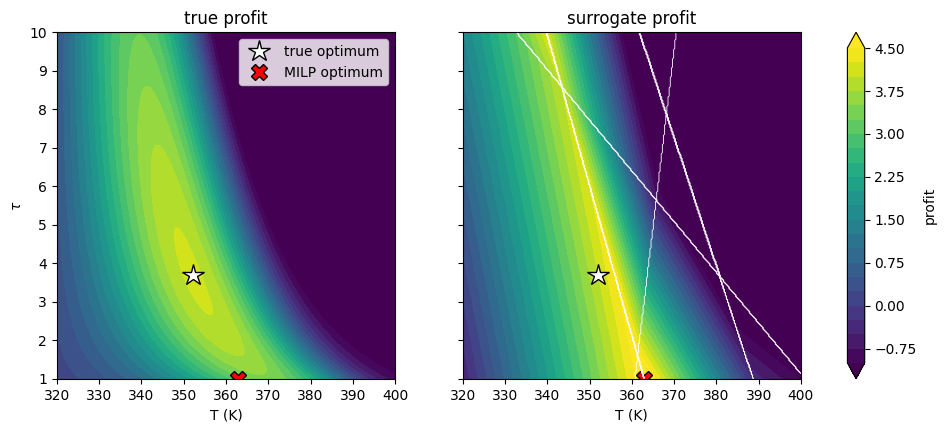

In [6]:
g0, g1 = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
G = np.c_[g0.ravel(), g1.ravel()]

def surrogate_profit(model, G):
    return price * model.predict(G, hard=True) - c_T * (G[:, 0] - 320) - c_tau * G[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
levels = np.linspace(-1, 4.5, 23)
for ax, Z, title in ((axes[0], profit(G), "true profit"),
                     (axes[1], surrogate_profit(model, G), "surrogate profit")):
    cs = ax.contourf(g0, g1, Z.reshape(g0.shape), levels=levels, cmap="viridis", extend="both")
    ax.plot(*x_true, "w*", ms=16, mec="k", label="true optimum")
    ax.plot(*x_milp, "rX", ms=12, mec="k", label="MILP optimum")
    ax.set(xlabel="T (K)", title=title)
leaves = model.apply(G).reshape(g0.shape)
axes[1].contour(g0, g1, leaves, levels=np.unique(leaves)[:-1] + 0.5, colors="w", linewidths=0.6)
axes[0].set_ylabel(r"$\tau$")
axes[0].legend(loc="upper right")
fig.colorbar(cs, ax=axes, label="profit")
plt.show()

## Big-M or convex hull

Both reformulations give the same MILP optimum, but they differ in the strength of their LP relaxation: the bound you get when the binaries are relaxed to $[0, 1]$. The hull relaxation is the convex hull of the union of the leaf models, the tightest possible, and it needs extra disaggregated copies of the variables. Big-M is smaller but weaker. On a tree this size both solve instantly. The difference in relaxation strength starts to matter once a surrogate is one piece of a large model.

In [7]:
for method in ("bigm", "hull"):
    m_, tree_ = build(model, (lo, hi), method=method)
    x_, p_, _, dt = solve(m_, tree_, model, (lo, hi))
    relaxed = m_.clone()
    pyo.TransformationFactory("core.relax_integer_vars").apply_to(relaxed)
    solver.solve(relaxed)
    n_var = sum(1 for _ in m_.component_data_objects(pyo.Var))
    n_con = sum(1 for _ in m_.component_data_objects(pyo.Constraint, active=True))
    print(f"{method:>5s}: {n_var:3d} vars, {n_con:3d} constraints, MILP {p_:.4f} "
          f"({dt * 1e3:.0f} ms), LP relaxation bound {pyo.value(relaxed.profit):.4f}")

 bigm:  13 vars,  61 constraints, MILP 5.0174 (15 ms), LP relaxation bound 7.0311


 hull:  43 vars, 114 constraints, MILP 5.0174 (13 ms), LP relaxation bound 5.0174


## The surrogate in a constraint

The tree output is an ordinary Pyomo variable, so it can appear in constraints too. Suppose downstream separation needs a yield of at least 0.62, more than the unconstrained solution delivers. We add that to the model we already solved and solve again. The surrogate is what enforces the constraint, so it holds for the true model only up to the surrogate error. We print the true yield to check.

In [8]:
m.min_yield = pyo.Constraint(expr=m.yB >= 0.62)
x_c, p_c, _, _ = solve(m, tree, model, (lo, hi))
print(f"T = {x_c[0]:.2f} K, tau = {x_c[1]:.3f}: profit predicted {p_c:.4f}, true {profit(x_c[None])[0]:.4f}")
print(f"  y_B surrogate {pyo.value(m.yB):.4f}, true {yield_B(x_c[None])[0]:.4f}")
m.del_component(m.min_yield)

T = 352.31 K, tau = 5.132: profit predicted 4.3372, true 3.7118
  y_B surrogate 0.6200, true 0.5575


## Closing the gap: trust-region refinement

The first MILP solution is well off. It sits on the edge $\tau = 1$, where the yield rises steeply and the global surrogate overestimates it badly, so the predicted profit is far above the true one. That is typical: the optimizer is drawn to wherever the surrogate overestimates the profit, so its optimum is biased upward even when the RMSE is small. The same error makes the yield constraint above unreliable. Near the optimum the profit surface is also flat, so small errors in the surrogate move the solution a long way.

A global surrogate cannot be accurate everywhere. A standard fix is to refine locally. We shrink the box to half its width around the current solution, sample 150 new points there, refit, and solve the MILP restricted to that box. Each round is one tree fit and one MILP.

In [9]:
history = [(x_milp, p_milp, (lo, hi))]
b_lo, b_hi = lo, hi
x_k = x_milp
for k in range(3):
    w = (b_hi - b_lo) / 4
    b_lo, b_hi = np.maximum(lo, x_k - w), np.minimum(hi, x_k + w)
    X_k = rng.uniform(b_lo, b_hi, (150, 2))
    y_k = yield_B(X_k) + 0.005 * rng.normal(size=150)
    model_k = DifferentiableTreeRegressor(**tree_kw).fit(X_k, y_k)
    m_k, tree_k = build(model_k, (b_lo, b_hi))
    x_k, p_k, _, _ = solve(m_k, tree_k, model_k, (b_lo, b_hi))
    history.append((x_k, p_k, (b_lo, b_hi)))

print("round       T      tau   predicted   true profit")
for k, (x_, p_, _) in enumerate(history):
    print(f"{k:5d}  {x_[0]:7.2f}  {x_[1]:6.3f}  {p_:9.4f}  {profit(x_[None])[0]:11.4f}")
print(f" true  {x_true[0]:7.2f}  {x_true[1]:6.3f}  {'':9s}  {p_true:11.4f}")

round       T      tau   predicted   true profit
    0   362.92   1.000     5.0174       3.1423
    1   350.62   3.250     4.2297       3.9458
    2   353.03   3.813     4.0719       4.0295
    3   353.16   3.531     4.0706       4.0489
 true   352.09   3.686                  4.0529


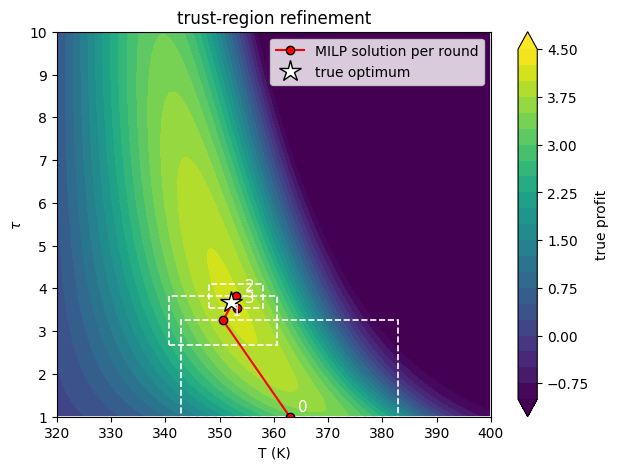

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
cs = ax.contourf(g0, g1, profit(G).reshape(g0.shape), levels=levels, cmap="viridis", extend="both")
for k, (x_, _, (bl, bh)) in enumerate(history):
    ax.add_patch(plt.Rectangle(bl, *(bh - bl), fill=False, ec="w", lw=1.2, ls="--" if k else "-"))
    ax.annotate(str(k), x_, xytext=(6, 4), textcoords="offset points", color="w", fontsize=11)
xs = np.array([h[0] for h in history])
ax.plot(xs[:, 0], xs[:, 1], "r-o", mec="k", label="MILP solution per round")
ax.plot(*x_true, "w*", ms=16, mec="k", label="true optimum")
ax.set(xlabel="T (K)", ylabel=r"$\tau$", title="trust-region refinement")
ax.legend(loc="upper right")
fig.colorbar(cs, label="true profit")
plt.show()

After three rounds, the true profit at the MILP solution is within about 0.1% of the true optimum, and the surrogate's prediction agrees with the true model there to within about 0.5%. Each round only needs samples in a small box, which is cheap when the true model is an expensive simulation.

## Summary

`export.to_pyomo(model, m, x=..., y=..., bounds=..., method=...)` turns a hardened tree into a Pyomo block that any Pyomo MILP solver can handle, with all bounds derived from the tree, and `leaf_from_pyomo` with `repair_solution` maps the solution back to the crisp tree. Two habits make the results trustworthy. Use a continuous (tied-split) tree so the solver cannot exploit jumps. And always evaluate the optimum with the true model, refining locally when the surrogate is optimistic there.